# Neuroblastoma — compare four treatment arms with MultiScorer

Do profiles at intermediate positions on the cycling-to-neuronal expression axis occupy similar neighborhoods across treatments? The experimental axis has **four conditions**. The biological model has **one reported maturation continuum**. We use its two extremes as observed destinations and score middle profiles against both. Two ends of the continuum are sufficient for this question. The six published clusters include intermediate stages. [Original study, Figure 6](https://doi.org/10.1073/pnas.2502483122)

The executed example uses a symmetric expression-neighborhood graph before row normalization. Walks on this graph measure proximity to observed states, and have no measured time direction. A velocity-based commitment interpretation requires the optional matched splicing-based graph described in notebook 23.

In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
import scCS
from scipy import sparse
from IPython.display import display

PROJECT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "benchmarks/validation/neuroblastoma_expression.py").exists()
)
sys.path.insert(0, str(PROJECT))
# The helper is available once the source checkout is on sys.path.
from benchmarks.validation.neuroblastoma_inputs import public_manifest  # noqa: E402

DATA = PROJECT / "data/neuroblastoma"
OUT = PROJECT / "tutorial_outputs/neuroblastoma"
OUT.mkdir(parents=True, exist_ok=True)
GROUPS = ["CTRL", "RA", "NEN", "RA+NEN"]
manifest = public_manifest()[["sample","library","condition","biological_replicate"]]
expression = OUT / "expression.h5ad"
profiles = OUT / "eligible_profiles.csv.gz"
missing = [path.name for path in (expression, profiles) if not path.is_file()]
if missing:
    raise FileNotFoundError(
        f"Run notebook 23 (Neuroblastoma inputs) first to generate {', '.join(missing)} in {OUT}."
    )
a = ad.read_h5ad(expression)
full = pd.read_csv(profiles, index_col=0)
assert a.obs_names.is_unique and set(a.obs.tumor) == set(manifest.library)

## Use common state definitions in all four arms

Compute pooled 20th, 40th, 60th and 80th percentiles of neuronal minus cycling expression in the tumor-balanced sample. Use the bottom and top fifths as endpoints and the middle fifth as the population to score. Keep the shoulders as background graph context. Labels are quantile-defined expression states and do not reproduce the authors’ clusters. Inspect each tumor’s representation and held-out genes before interpreting the comparison.

Barcodes with neither labeling module detected stay in the background. Among the middle-score profiles, a tied or near-zero score can otherwise represent a lack of information.

In [2]:
from benchmarks.validation.neuroblastoma_expression import CYCLING, HELD_OUT, IDENTITY, NEURON

q20,q40,q60,q80 = a.obs.balance.quantile([.2,.4,.6,.8])
FATES = ["Cycling-enriched", "Neuron-enriched"]
ROOT = "Intermediate"
def state(frame):
    score = frame.balance
    evidence = (frame.neuronal_score > 0) | (frame.cycling_score > 0)
    return np.select([score <= q20, score >= q80, score.between(q40,q60) & evidence],
                     [FATES[0], FATES[1], ROOT], default="Shoulder")
a.obs["state"] = state(a.obs)
full["state"] = state(full)
display(pd.crosstab([a.obs.condition,a.obs.tumor],a.obs.state))
display(a.obs.groupby("state",observed=True)[HELD_OUT].mean().round(2))
composition = pd.crosstab([full.condition,full.tumor],full.state,normalize="index")
display(composition.round(3))
composition.to_csv(OUT / "expression_state_fractions.csv")

state            Cycling-enriched  Intermediate  Neuron-enriched  Shoulder
condition tumor                                                           
CTRL      C1                  148           169              185       298
          C2                  112           199              174       315
NEN       N1                  208           176               95       321
          N2                  171           174              127       328
RA        R1                  150           156              206       288
          R2                  162           159              198       281
RA+NEN    RN1                 158           164              142       336
          RN2                 171           166              153       310

,NEFL,STMN2,MCM2,PCNA
state,,,,
Cycling-enriched,0.32,1.10,0.32,1.78
Intermediate,0.28,1.19,0.22,1.12
Neuron-enriched,0.33,1.97,0.14,0.65
Shoulder,0.26,1.29,0.23,1.19


state            Cycling-enriched  Intermediate  Neuron-enriched  Shoulder
condition tumor                                                           
CTRL      C1                0.185         0.220            0.227     0.368
          C2                0.141         0.230            0.218     0.410
NEN       N1                0.229         0.244            0.126     0.401
          N2                0.214         0.231            0.157     0.397
RA        R1                0.177         0.203            0.253     0.367
          R2                0.181         0.195            0.264     0.360
RA+NEN    RN1               0.194         0.218            0.203     0.385
          RN2               0.208         0.219            0.199     0.374

## Build the graph independently of the labeling panels

Exclude the identity, cycling, neuronal and held-out genes from PCA. Other genes can correlate with these programs. Compute a shared expression neighborhood using up to 2,000 variable genes. Row-normalized connectivity defines the reference transition matrix. The optional velocity graph uses the same cell IDs and endpoints for comparison.

Graphs supplied: ['Expression neighborhood']


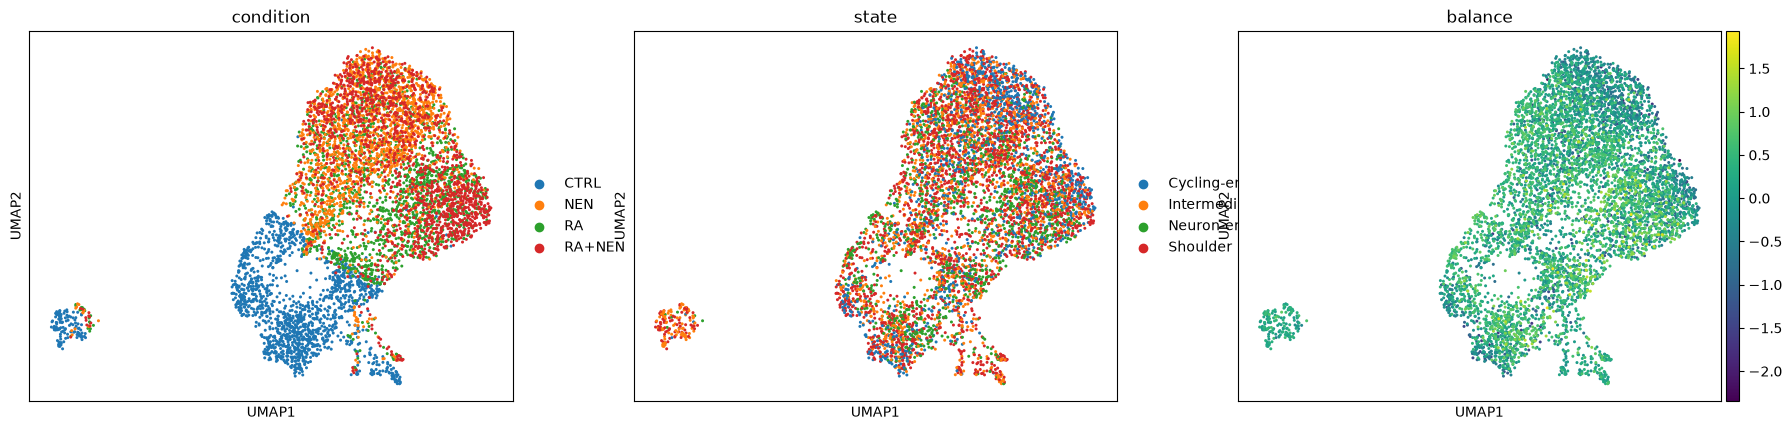

In [3]:
sc.pp.normalize_total(a,target_sum=1e4)
sc.pp.log1p(a)
mask = ~a.var.symbol.isin(IDENTITY + CYCLING + NEURON + HELD_OUT) & ~a.var.symbol.str.startswith(
    ("MT-", "RPS", "RPL")
)
graph_data = a[:,mask].copy()
sc.pp.filter_genes(graph_data,min_cells=10)
sc.pp.highly_variable_genes(graph_data,n_top_genes=2000,subset=True)
sc.pp.pca(graph_data,n_comps=30,random_state=19)
sc.pp.neighbors(graph_data,n_neighbors=30,n_pcs=30,random_state=19)
sc.tl.umap(graph_data,random_state=19)
sc.pl.umap(graph_data,color=["condition","state","balance"],ncols=3,show=False)
plt.show()
conn = graph_data.obsp["connectivities"].astype(float).tocsr()
mass = np.asarray(conn.sum(axis=1)).ravel()
assert (mass>0).all()
graphs = {"Expression neighborhood": sparse.diags(1/mass) @ conn}
velocity_path = os.environ.get("SCCS_NEUROBLASTOMA_VELOCITY_H5AD")
if velocity_path:
    v = ad.read_h5ad(velocity_path)
    assert v.obs_names.is_unique and set(v.obs_names) == set(a.obs_names)
    v = v[a.obs_names].copy()
    for layer in ["spliced","unspliced"]:
        x = v.layers[layer]
        values = x.data if sparse.issparse(x) else np.asarray(x)
        assert np.isfinite(values).all() and values.min() >= 0 and values.max() > 0
    tv = sparse.csr_matrix(v.obsp["T_velocity"])
    assert np.isfinite(tv.data).all() and tv.data.min() >= 0
    np.testing.assert_allclose(np.asarray(tv.sum(axis=1)).ravel(),1,atol=1e-6)
    graphs["RNA velocity"] = tv
    import scvelo as scv
    if "velocity_graph" in v.uns and "X_umap" in v.obsm:
        scv.pl.velocity_embedding_stream(v,basis="umap",color="tumor",show=False)
        plt.show()
    if "velocity_confidence" in v.obs:
        display(v.obs.groupby("tumor", observed=True).velocity_confidence.agg(["size","median"]))
print("Graphs supplied:",list(graphs))

## Measure reach to the two extremes from intermediate profiles

Select all annotated endpoint cells as anchors so both extremes have an explicit common definition. The ordering coordinate measures distance from the middle of the expression axis and determines the star layout. With every endpoint cell anchored, ordering has no effect on anchor membership. Fit a pooled graph and repeat with edges confined to each tumor. All four arms share state definitions, kinetic inputs when available, and the effective horizon of 64 steps.

In [4]:
a.obs["distance_from_center"] = (a.obs.balance - a.obs.balance.median()).abs()
rows = []
for graph, T in graphs.items():
    for scope in ["pooled","replicate"]:
        scorer = scCS.MultiScorer(a,root=ROOT,branches=FATES,obs_key="state",
                                  condition_obs_key="condition",replicate_obs_key="tumor",condition_order=GROUPS)
        scorer.build_embedding(ordering_metric="distance_from_center",cache_subset=False,verbose=False)
        scorer.fit(transition_matrix=T,transition_scope=scope,scoring_mode="future_fate",
                   future_fate_options={"effective_horizon":64,"min_anchor_cells":a.n_obs},verbose=False)
        res = scorer.score_all_conditions(
            population="root", min_cells=1, min_replicates=2, write_to_adata=False, verbose=False
        )
        for condition,r in res.items():
            ids = pd.Index(r.cell_ids)
            assert list(r.fate_names) == FATES
            np.testing.assert_allclose(r.commitment_contribution.sum(axis=1),r.commitment_strength)
            for tumor in a.obs.loc[ids,"tumor"].unique():
                use = a.obs.loc[ids,"tumor"].eq(tumor).to_numpy()
                defined = use & r.affinity_defined
                rows.append(
                    dict(
                        graph=graph,
                        scope=scope,
                        condition=condition,
                        tumor=tumor,
                        roots=int(use.sum()),
                        defined=int(defined.sum()),
                        DFR=r.commitment_strength[use].mean(),
                        neuron_contribution=r.commitment_contribution[use, 1].mean(),
                        neuron_CFA=r.directional_affinity[defined, 1].mean()
                        if defined.any()
                        else np.nan,
                    )
                )
scores = pd.DataFrame(rows)
scores.to_csv(OUT / "multiscorer_by_tumor.csv",index=False)
display(scores.round(4))

<ipython-input-4-cfca026cfb48>:10: RuntimeWarning: Condition 'CTRL' contains only 2 biological replicates. Formal inference is available but has limited resolution; at least 4 and preferably 5-6 replicates per condition are recommended.
  res = scorer.score_all_conditions(population="root",min_cells=1,min_replicates=2,write_to_adata=False,verbose=False)
<ipython-input-4-cfca026cfb48>:10: RuntimeWarning: Condition 'RA' contains only 2 biological replicates. Formal inference is available but has limited resolution; at least 4 and preferably 5-6 replicates per condition are recommended.
  res = scorer.score_all_conditions(population="root",min_cells=1,min_replicates=2,write_to_adata=False,verbose=False)
<ipython-input-4-cfca026cfb48>:10: RuntimeWarning: Condition 'NEN' contains only 2 biological replicates. Formal inference is available but has limited resolution; at least 4 and preferably 5-6 replicates per condition are recommended.
  res = scorer.score_all_conditions(population="root",

,graph,scope,condition,tumor,roots,defined,DFR,neuron_contribution,neuron_CFA
0,Expression neighborhood,pooled,CTRL,C1,169,169,0.9241,0.5509,0.5973
1,Expression neighborhood,pooled,CTRL,C2,199,199,0.9070,0.5958,0.6578
2,Expression neighborhood,pooled,RA,R1,156,156,0.9482,0.5925,0.6242
3,Expression neighborhood,pooled,RA,R2,159,159,0.9498,0.4997,0.5269
4,Expression neighborhood,pooled,NEN,N1,176,176,0.9441,0.5487,0.5817
5,Expression neighborhood,pooled,NEN,N2,174,174,0.9424,0.5467,0.5810
6,Expression neighborhood,pooled,RA+NEN,RN1,164,164,0.9531,0.4610,0.4842
7,Expression neighborhood,pooled,RA+NEN,RN2,166,166,0.9516,0.4825,0.5076
8,Expression neighborhood,replicate,CTRL,C1,169,169,0.9120,0.5485,0.6053
9,Expression neighborhood,replicate,CTRL,C2,199,199,0.8918,0.6094,0.6904


## Compare treatments at the tumor level

Average the two tumor means with equal weight. Display each arm and each active treatment minus control, with RA+NEN minus control as the primary contrast. Undefined tumor outcomes propagate to the arm summary. Two tumors per group give limited information about biological variability. A two-versus-two exact two-sided label permutation has six assignments and a smallest attainable p-value of 1/3.

,DFR,neuron_contribution,neuron_CFA
condition,,,
CTRL,0.9155,0.5734,0.6276
RA,0.9490,0.5461,0.5756
NEN,0.9433,0.5477,0.5813
RA+NEN,0.9523,0.4717,0.4959


,DFR,neuron_contribution,neuron_CFA
condition,,,
CTRL,0.9019,0.5790,0.6478
RA,0.9339,0.5585,0.5997
NEN,0.9092,0.5122,0.5660
RA+NEN,0.9256,0.4705,0.5094


,DFR,neuron_contribution,neuron_CFA,graph,scope
condition,,,,,
RA,0.0335,-0.0272,-0.0520,Expression neighborhood,pooled
NEN,0.0277,-0.0256,-0.0462,Expression neighborhood,pooled
RA+NEN,0.0368,-0.1016,-0.1317,Expression neighborhood,pooled
RA,0.0320,-0.0204,-0.0481,Expression neighborhood,replicate
NEN,0.0073,-0.0667,-0.0818,Expression neighborhood,replicate
RA+NEN,0.0237,-0.1085,-0.1384,Expression neighborhood,replicate


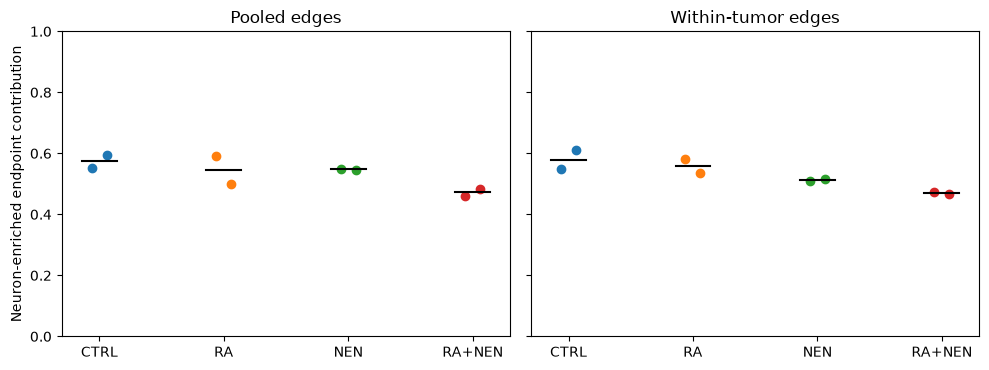

In [5]:
metrics = ["DFR","neuron_contribution","neuron_CFA"]
means = scores.groupby(["graph", "scope", "condition"], observed=True)[metrics].agg(
    lambda x: x.mean(skipna=False)
)
differences = []
for (graph,scope), table in means.groupby(level=["graph","scope"]):
    arm = table.droplevel(["graph","scope"]).reindex(GROUPS)
    display(arm.round(4))
    differences.append(arm.iloc[1:].sub(arm.loc["CTRL"]).assign(graph=graph,scope=scope))
delta = pd.concat(differences)
display(delta.round(4))
delta.to_csv(OUT / "contrasts_vs_control.csv")
fig, axes = plt.subplots(1,2,figsize=(10,3.8),sharey=True)
for scope,ax in zip(["pooled","replicate"],axes):
    for i,g in enumerate(GROUPS):
        y = scores.loc[
            (scores.graph == "Expression neighborhood")
            & (scores.scope == scope)
            & (scores.condition == g),
            "neuron_contribution",
        ]
        ax.scatter(i+np.linspace(-.06,.06,len(y)),y)
        ax.plot([i-.14,i+.14],[y.mean()]*2,color="black")
    ax.set(
        xticks=range(4),
        xticklabels=GROUPS,
        ylim=(0, 1),
        title="Pooled edges" if scope == "pooled" else "Within-tumor edges",
    )
axes[0].set_ylabel("Neuron-enriched endpoint contribution")
fig.tight_layout()
plt.show()

## Interpretation

All eight tumors contribute intermediate cells. Among 1,363 such profiles, RA+NEN minus control is **+0.037 for reach to either expression extreme** and **-0.102 for the neuron-enriched contribution** on the pooled reference. Confining edges to individual tumors gives a neuron-enriched contribution contrast of -0.108. Each arm mean weights its two tumors equally.

The intermediate profiles in the combination arm can access the ends of the expression axis, with a smaller contribution from neuronal neighborhoods than in controls at this graph scale. An undirected expression neighborhood permits steps in either direction. It cannot identify the direction in which cells are differentiating. The published authors used their velocity field, cell selection and phenotypic measurements to assess differentiation. Our two endpoint labels, root gates and human-reference selection define a separate descriptive comparison. A matched RNA-velocity graph would directly test whether direction changes the treatment contrast.
